In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.metrics import ConfusionMatrixDisplay

In [13]:
# === User configuration ===
csv_path = "measures029"
# list_of_experiments = ['A', 'B', 'C']
list_of_experiments = ['A']
file_type = "csv"

plt.style.use('seaborn-v0_8')

In [14]:
# === Plotting function (server-wide metric only) ===
def plot_server_metrics(val_pivot, test_metric, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o', color='orange')
    plt.xlabel('Epoch')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


In [15]:
# === Plotting function ===
def plot_server_metrics(val_pivot, test_metric, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o', color='orange')
    plt.xlabel('Epoch')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [16]:
dfs = {}

for xp in list_of_experiments:
    df = pd.read_csv(f"{csv_path}{xp}.{file_type}")
    df['validation'] = df['validation'].astype(bool)
    
    df_train = df[df['validation'] == False]
    df_val = df[df['validation'] == True]

    dfs[xp] = {"users": {}}  # store per-user pivots here
    
    users = df['user'].unique()
    users.sort()  # sorts the array in place
    for user in users:
        cent_df_train = df_train[df_train['user'] == user]
        cent_df_val = df_val[df_val['user'] == user]
        
        cent_train_pivot = cent_df_train.pivot(index='epoch', columns='metric', values='values').astype(float)
        cent_val_pivot = cent_df_val.pivot(index='epoch', columns='metric', values='values')
        
        excluded_column = 'metrics.TEST_CONF'
        cent_val_pivot.loc[:, cent_val_pivot.columns != excluded_column] = (
            cent_val_pivot.loc[:, cent_val_pivot.columns != excluded_column].astype(float)
        )
        
        dfs[xp]["users"][user] = {
            "df_train": cent_df_train,
            "df_val": cent_df_val,
            "train_pivot": cent_train_pivot,
            "val_pivot": cent_val_pivot
        }

print("Data loaded and prepared for experiments:", list(dfs.keys()))
colors = plt.get_cmap('tab10', len(users))  # modern API

Data loaded and prepared for experiments: ['A']



=== Experiment A ===


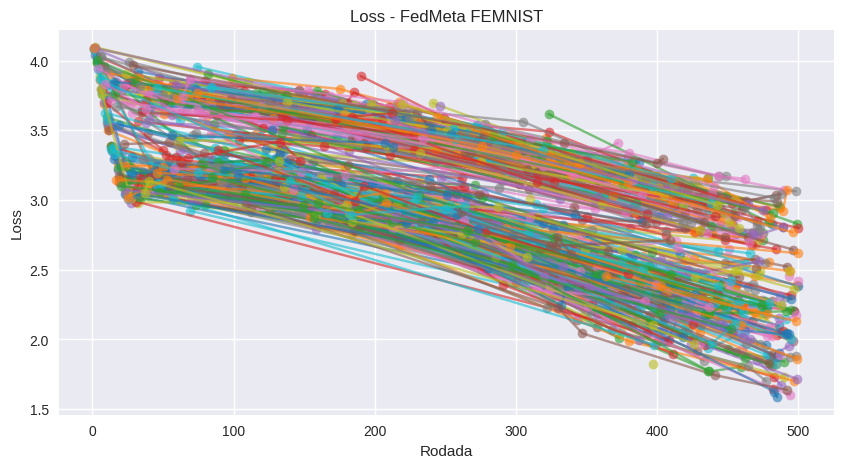

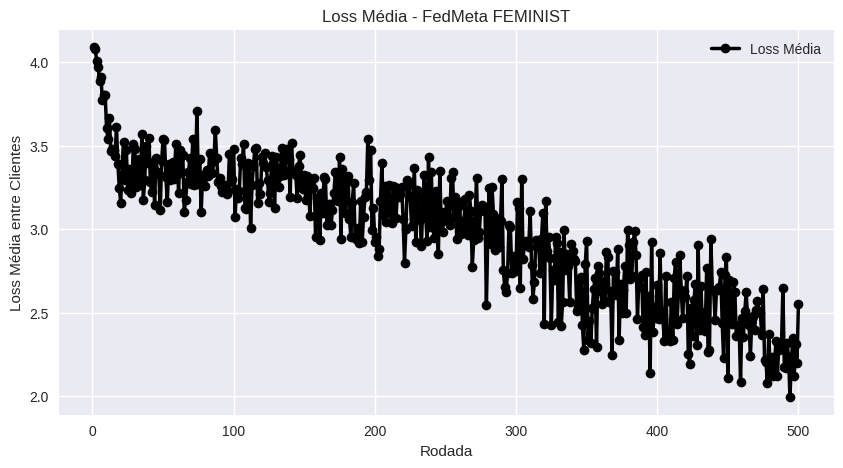

In [17]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")

    users_xp = sorted(dfs[xp]["users"].keys())
    cmap = plt.get_cmap("tab10")

    # -------------------------
    # 1) Plot per-user precisions
    # -------------------------
    plt.figure(figsize=(10, 5))
    all_precisions = []

    for i, user in enumerate(users_xp):
        val_pivot = dfs[xp]["users"][user]["val_pivot"]

        if "metrics.LOSS" not in val_pivot.columns:
            continue

        # Ensure numeric epoch index and numeric values
        idx_num = pd.to_numeric(val_pivot.index, errors="coerce")
        prec_series = val_pivot["metrics.LOSS"].copy()
        prec_series.index = idx_num
        prec_series = pd.to_numeric(prec_series, errors="coerce")
        prec_series = prec_series[~prec_series.index.isna()]
        if prec_series.empty:
            continue

        prec_series.name = str(user)
        all_precisions.append(prec_series)

        plt.plot(prec_series.index.astype(int), prec_series.values,
                 marker='o', label=f'Usuário {user}', alpha=0.6, color=cmap(i % 10))

    plt.xlabel('Rodada')
    plt.ylabel('Loss')
    plt.title(f'Loss - FedMeta FEMNIST')
    #plt.legend(ncol=3, fontsize='small')
    plt.grid(True)
    plt.show()


    # -------------------------
    # 2) Plot average precision
    # -------------------------
    if not all_precisions:
        print(f"No TEST_PREC found for any user in {xp}; skipping average plot.")
        continue

    df_all = pd.concat(all_precisions, axis=1)
    df_all.columns = [str(c) for c in df_all.columns]
    df_all = df_all.sort_index()

    avg_precision = df_all.mean(axis=1, skipna=True)

    plt.figure(figsize=(10, 5))
    plt.plot(avg_precision.index.astype(int), avg_precision.values,
             marker='o', color='black', linewidth=2.5, label='Loss Média')
    plt.xlabel('Rodada')
    plt.ylabel('Loss Média entre Clientes')
    plt.title(f'Loss Média - FedMeta FEMINIST')
    plt.legend()
    plt.grid(True)
    plt.show()



=== Experiment A ===


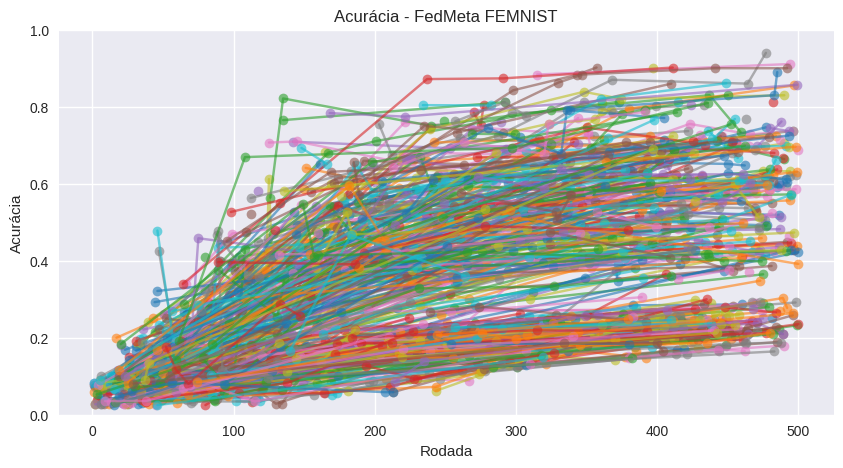

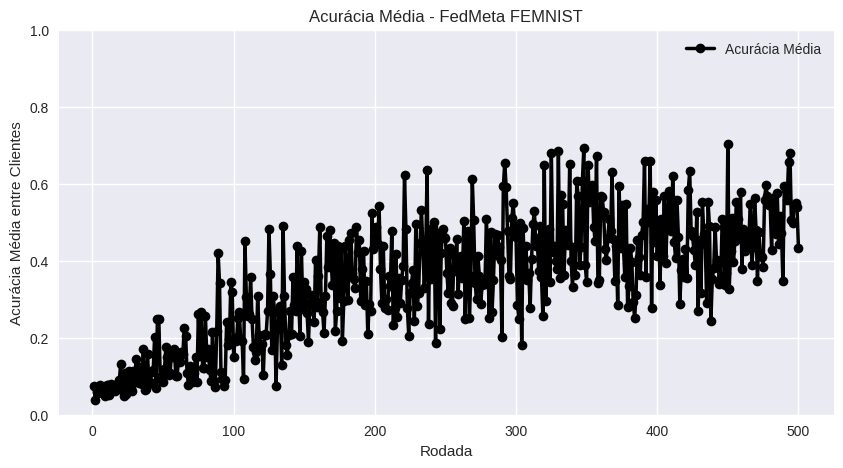

In [18]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")

    # per-experiment users (important!)
    users_xp = sorted(dfs[xp]["users"].keys())
    cmap = plt.get_cmap("tab10")

    # -------------------------
    # 1) Plot per-user accuracies
    # -------------------------
    plt.figure(figsize=(10, 5))
    all_accuracies = []  # will store Series: index=epoch, values=accuracy

    for i, user in enumerate(users_xp):
        val_pivot = dfs[xp]["users"][user]["val_pivot"]

        # skip users that have no TEST_ACC column
        if "metrics.TEST_ACC" not in val_pivot.columns:
            continue

        # Make sure epoch index and series values are numeric
        # (val_pivot.index is expected to be epoch numbers but may be strings)
        idx_num = pd.to_numeric(val_pivot.index, errors="coerce")
        acc_series = val_pivot["metrics.TEST_ACC"].copy()
        acc_series.index = idx_num  # set numeric epoch index (NaN if cannot convert)
        acc_series = pd.to_numeric(acc_series, errors="coerce")  # coerce bad strings -> NaN

        # drop any NaN index rows (rows where epoch could not be parsed)
        acc_series = acc_series[~acc_series.index.isna()]
        if acc_series.empty:
            continue

        # name column and store
        acc_series.name = str(user)
        all_accuracies.append(acc_series)

        # plot per-user (light color)
        plt.plot(acc_series.index.astype(int), acc_series.values,
                 marker='o', label=f'Usuário {user}', alpha=0.6, color=cmap(i % 10))

    plt.xlabel('Rodada')
    plt.ylabel('Acurácia')
    plt.ylim(0.0, 1.0)
    plt.title(f'Acurácia - FedMeta FEMNIST')
    #plt.legend(ncol=3, fontsize='small')
    plt.grid(True)
    plt.show()

    # -------------------------
    # 2) Build matrix and plot average
    # -------------------------
    if not all_accuracies:
        print(f"No TEST_ACC found for any user in {xp}; skipping average plot.")
        continue

    # Align into epochs x users matrix (missing -> NaN) and sort by epoch
    df_all = pd.concat(all_accuracies, axis=1)
    # ensure unique column names (strings)
    df_all.columns = [str(c) for c in df_all.columns]
    df_all = df_all.sort_index()

    
    # Compute epoch-wise average (ignore NaNs)
    avg_accuracy = df_all.mean(axis=1, skipna=True)

    # Plot average
    plt.figure(figsize=(10, 5))
    plt.plot(avg_accuracy.index.astype(int), avg_accuracy.values,
             marker='o', color='black', linewidth=2.5, label='Acurácia Média')
    plt.xlabel('Rodada')
    plt.ylabel('Acurácia Média entre Clientes')
    plt.ylim(0.0, 1.0)
    plt.title(f'Acurácia Média - FedMeta FEMNIST')
    plt.legend()
    plt.grid(True)
    plt.show()


=== Experiment A ===


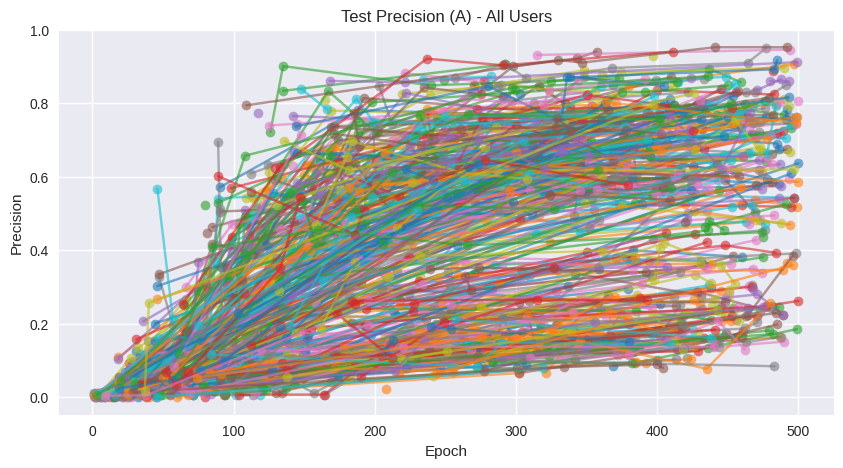

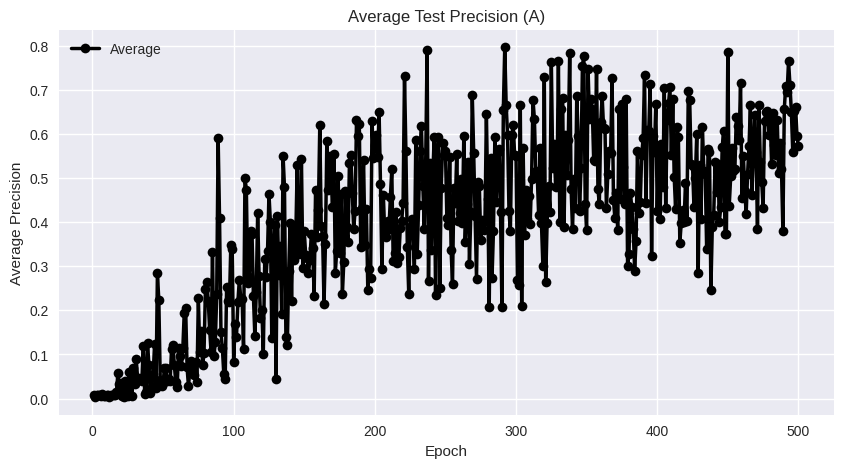

In [19]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")

    users_xp = sorted(dfs[xp]["users"].keys())
    cmap = plt.get_cmap("tab10")

    # -------------------------
    # 1) Plot per-user precisions
    # -------------------------
    plt.figure(figsize=(10, 5))
    all_precisions = []

    for i, user in enumerate(users_xp):
        val_pivot = dfs[xp]["users"][user]["val_pivot"]

        if "metrics.TEST_PREC" not in val_pivot.columns:
            continue

        # Ensure numeric epoch index and numeric values
        idx_num = pd.to_numeric(val_pivot.index, errors="coerce")
        prec_series = val_pivot["metrics.TEST_PREC"].copy()
        prec_series.index = idx_num
        prec_series = pd.to_numeric(prec_series, errors="coerce")
        prec_series = prec_series[~prec_series.index.isna()]
        if prec_series.empty:
            continue

        prec_series.name = str(user)
        all_precisions.append(prec_series)

        plt.plot(prec_series.index.astype(int), prec_series.values,
                 marker='o', label=f'User {user}', alpha=0.6, color=cmap(i % 10))

    plt.xlabel('Epoch')
    plt.ylabel('Precision')
    plt.title(f'Test Precision ({xp}) - All Users')
    #plt.legend(ncol=3, fontsize='small')
    plt.grid(True)
    plt.show()


    # -------------------------
    # 2) Plot average precision
    # -------------------------
    if not all_precisions:
        print(f"No TEST_PREC found for any user in {xp}; skipping average plot.")
        continue

    df_all = pd.concat(all_precisions, axis=1)
    df_all.columns = [str(c) for c in df_all.columns]
    df_all = df_all.sort_index()

    avg_precision = df_all.mean(axis=1, skipna=True)

    plt.figure(figsize=(10, 5))
    plt.plot(avg_precision.index.astype(int), avg_precision.values,
             marker='o', color='black', linewidth=2.5, label='Average')
    plt.xlabel('Epoch')
    plt.ylabel('Average Precision')
    plt.title(f'Average Test Precision ({xp})')
    plt.legend()
    plt.grid(True)
    plt.show()



=== Experiment A ===


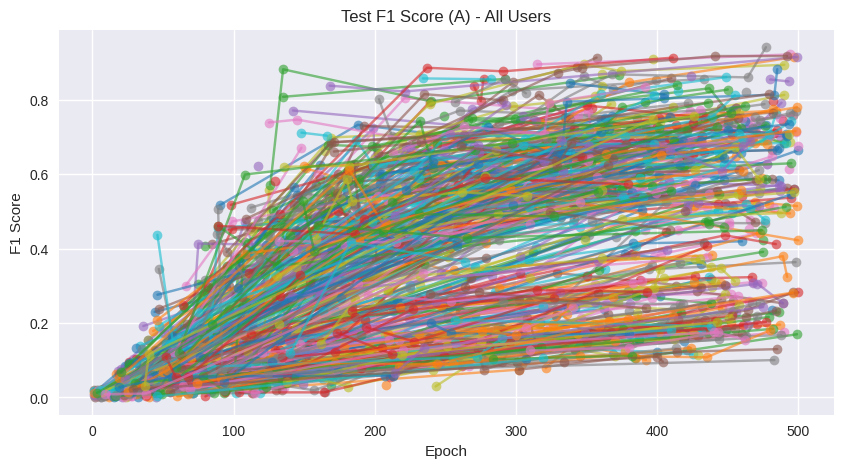

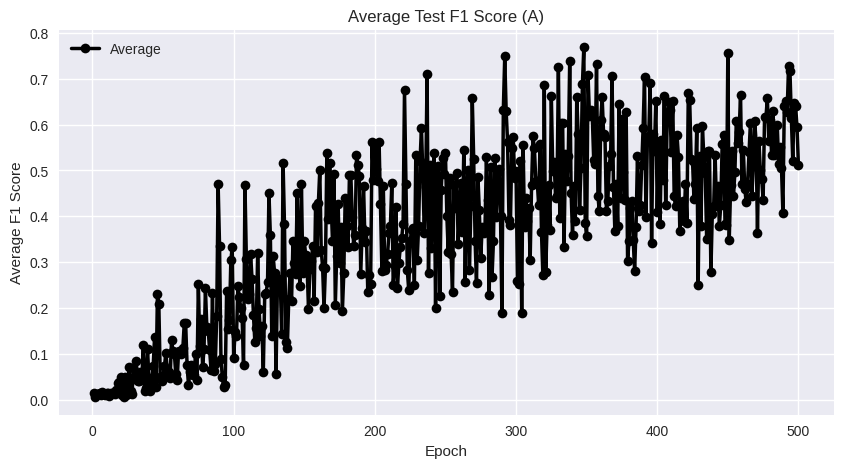

In [20]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")

    users_xp = sorted(dfs[xp]["users"].keys())
    cmap = plt.get_cmap("tab10")

    # -------------------------
    # 1) Plot per-user F1 scores
    # -------------------------
    plt.figure(figsize=(10, 5))
    all_f1 = []

    for i, user in enumerate(users_xp):
        val_pivot = dfs[xp]["users"][user]["val_pivot"]

        if "metrics.TEST_F1" not in val_pivot.columns:
            continue

        # Ensure numeric epoch index and values
        idx_num = pd.to_numeric(val_pivot.index, errors="coerce")
        f1_series = val_pivot["metrics.TEST_F1"].copy()
        f1_series.index = idx_num
        f1_series = pd.to_numeric(f1_series, errors="coerce")
        f1_series = f1_series[~f1_series.index.isna()]
        if f1_series.empty:
            continue

        f1_series.name = str(user)
        all_f1.append(f1_series)

        plt.plot(f1_series.index.astype(int), f1_series.values,
                 marker='o', label=f'User {user}', alpha=0.6, color=cmap(i % 10))

    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.title(f'Test F1 Score ({xp}) - All Users')
    #plt.legend(ncol=3, fontsize='small')
    plt.grid(True)
    plt.show()

    # -------------------------
    # 2) Plot average F1
    # -------------------------
    if not all_f1:
        print(f"No TEST_F1 found for any user in {xp}; skipping average plot.")
        continue

    df_all = pd.concat(all_f1, axis=1)
    df_all.columns = [str(c) for c in df_all.columns]
    df_all = df_all.sort_index()

    avg_f1 = df_all.mean(axis=1, skipna=True)

    plt.figure(figsize=(10, 5))
    plt.plot(avg_f1.index.astype(int), avg_f1.values,
             marker='o', color='black', linewidth=2.5, label='Average')
    plt.xlabel('Epoch')
    plt.ylabel('Average F1 Score')
    plt.title(f'Average Test F1 Score ({xp})')
    plt.legend()
    plt.grid(True)
    plt.show()


In [21]:
# Collect metrics for averaging
acc_list = []
prec_list = []
f1_list = []

for xp in dfs:
    acc_users = []
    prec_users = []
    f1_users = []
    
    for user, user_data in dfs[xp]["users"].items():
        val_pivot = user_data['val_pivot']
        max_index = val_pivot['metrics.TEST_ACC'].idxmax()
        
        acc_users.append(val_pivot['metrics.TEST_ACC'][max_index])
        prec_users.append(val_pivot['metrics.TEST_PREC'][max_index])
        f1_users.append(val_pivot['metrics.TEST_F1'][max_index])
    
    # Average across users for this experiment
    acc_avg = sum(acc_users) / len(acc_users)
    prec_avg = sum(prec_users) / len(prec_users)
    f1_avg = sum(f1_users) / len(f1_users)
    
    acc_list.append(acc_avg)
    prec_list.append(prec_avg)
    f1_list.append(f1_avg)
    
    print(f"\n=== Best Epoch for Experiment {xp} (averaged over users) ===")
    print(f"Balanced Accuracy: {acc_avg:.4f}")
    print(f"Precision: {prec_avg:.4f}")
    print(f"F1 Score: {f1_avg:.4f}")

# Print averages across experiments
print("\n=== Average Across Experiments ===")
print(f"Average Balanced Accuracy: {sum(acc_list) / len(acc_list):.4f}")
print(f"Average Precision: {sum(prec_list) / len(prec_list):.4f}")
print(f"Average F1 Score: {sum(f1_list) / len(f1_list):.4f}")



=== Best Epoch for Experiment A (averaged over users) ===
Balanced Accuracy: 0.4140
Precision: 0.4783
F1 Score: 0.4496

=== Average Across Experiments ===
Average Balanced Accuracy: 0.4140
Average Precision: 0.4783
Average F1 Score: 0.4496


In [22]:
import re

output_file = f"{csv_path}.txt"

with open(output_file, "w") as f:
    f.write("=== Experiment Parameters ===\n")
    
    # Split csv_path into parts and write them
    parts = csv_path.split("_")
    for part in parts:
        match = re.match(r"([a-zA-Z]+)([0-9\.\-eE]+)", part)
        if match:
            name, value = match.groups()
            f.write(f"{name} {value}\n")
        else:
            f.write(f"{part}\n")
    
    f.write("\n=== Best Epoch Results per Experiment (averaged across users) ===\n")
    
    exp_acc_list = []
    exp_prec_list = []
    exp_f1_list = []
    
    for xp in dfs:
        acc_users = []
        prec_users = []
        f1_users = []
        
        for user, user_data in dfs[xp]["users"].items():
            val_pivot = user_data['val_pivot']
            max_index = val_pivot['metrics.TEST_ACC'].idxmax()
            
            acc_users.append(val_pivot['metrics.TEST_ACC'][max_index])
            prec_users.append(val_pivot['metrics.TEST_PREC'][max_index])
            f1_users.append(val_pivot['metrics.TEST_F1'][max_index])
            
            # Write per-user results
            f.write(f"\nExperiment {xp} - User {user}:\n")
            f.write(f"Balanced Accuracy: {val_pivot['metrics.TEST_ACC'][max_index]}\n")
            f.write(f"Precision: {val_pivot['metrics.TEST_PREC'][max_index]}\n")
            f.write(f"F1 Score: {val_pivot['metrics.TEST_F1'][max_index]}\n")
        
        # Average across users for this experiment
        acc_avg = sum(acc_users) / len(acc_users)
        prec_avg = sum(prec_users) / len(prec_users)
        f1_avg = sum(f1_users) / len(f1_users)
        
        exp_acc_list.append(acc_avg)
        exp_prec_list.append(prec_avg)
        exp_f1_list.append(f1_avg)
        
        f.write(f"\nExperiment {xp} (Averaged across users):\n")
        f.write(f"Balanced Accuracy: {acc_avg:.4f}\n")
        f.write(f"Precision: {prec_avg:.4f}\n")
        f.write(f"F1 Score: {f1_avg:.4f}\n")
    
    # Average across experiments
    f.write("\n=== Average Across Experiments (user-averaged) ===\n")
    f.write(f"Average Balanced Accuracy: {sum(exp_acc_list) / len(exp_acc_list):.4f}\n")
    f.write(f"Average Precision: {sum(exp_prec_list) / len(exp_prec_list):.4f}\n")
    f.write(f"Average F1 Score: {sum(exp_f1_list) / len(exp_f1_list):.4f}\n")

print(f"Results saved to {output_file}")


Results saved to measures029.txt
